# Single-galaxy halo fits

Fit both halos to one galaxy from the sample prepared in notebook 1.
Compare starting and fitted curves, then inspect their baryonic components and residuals.

Fixed disk and bulge mass-to-light ratios scale the baryonic velocity contributions. Signed component curves preserve the sign of each squared-speed term.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "models" / "fitting.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from models.results import FitConfig, result_tables
from models.fitting import fit_galaxy, initial_guesses
from utils.plotting import plot_halo_fit, plot_initial_optimized_comparison
INPUT_PATH = PROJECT_ROOT / "data/processed/selected_galaxy_rotation_curves.csv"
FIGURE_DIR = PROJECT_ROOT / "figures/halo_fits"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
GALAXY = "DDO154"
config = FitConfig()
joined = pd.read_csv(INPUT_PATH)
galaxy = joined.loc[joined.galaxy == GALAXY]
if galaxy.empty:
    raise ValueError(f"Galaxy not in sample: {GALAXY}")
guesses = initial_guesses(galaxy.v_obs.max(), config)
display(pd.DataFrame(guesses, columns=["initial_log_m200", "initial_concentration"]))

   initial_log_m200  initial_concentration
0         10.269453               5.807595
1         10.269453              11.615191
2         10.269453              23.230381
3         10.570483               5.807595
4         10.570483              11.615191
5         10.570483              23.230381
6         10.871513               5.807595
7         10.871513              11.615191
8         10.871513              23.230381

## Nine starts for each model
Initialization uses maximum observed velocity, not catalog Vflat. Convergence does not establish a good physical fit.

In [3]:
fits = [fit_galaxy(galaxy, model, config) for model in ("nfw", "burkert")]
summary, attempts, predictions = result_tables(fits)
display(summary)
display(attempts)

   galaxy    model  ...  mass_bound_hit  concentration_bound_hit
0  DDO154      nfw  ...           False                    False
1  DDO154  burkert  ...           False                    False

[2 rows x 15 columns]

    galaxy    model  start  ...        chi2  iterations  evaluated_at_bound
0   DDO154      nfw      1  ...  117.712081          20                True
1   DDO154      nfw      2  ...  117.712081          20                True
2   DDO154      nfw      3  ...  117.712081          24                True
3   DDO154      nfw      4  ...  117.712081          16                True
4   DDO154      nfw      5  ...  117.712081          20                True
5   DDO154      nfw      6  ...  117.712081          30                True
6   DDO154      nfw      7  ...  117.712081          16                True
7   DDO154      nfw      8  ...  117.712081          22                True
8   DDO154      nfw      9  ...  117.712081          25                True
9   DDO154  burkert      1  ...   12.436461          10                True
10  DDO154  burkert      2  ...   12.436461           9                True
11  DDO154  burkert      3  ...   12.436461          13                True
12  DDO154  

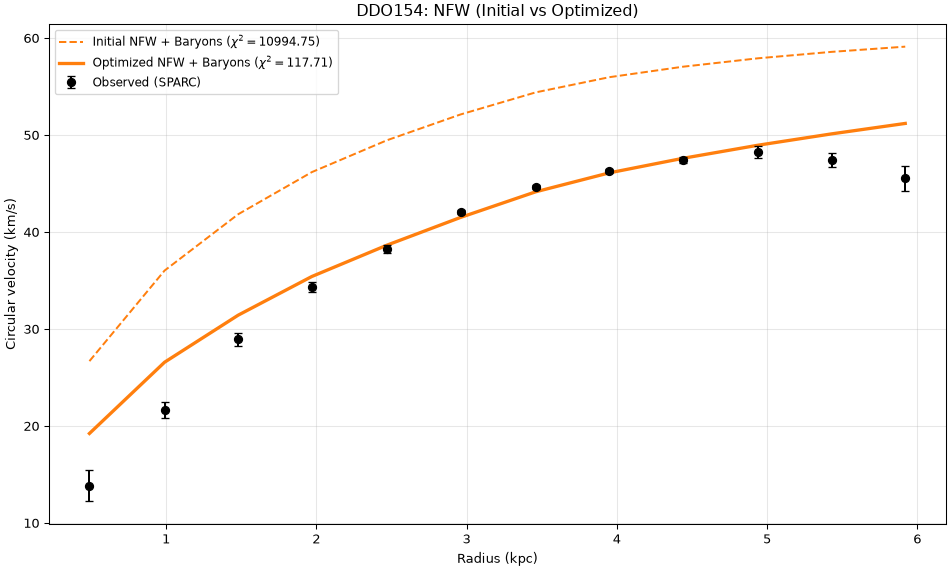

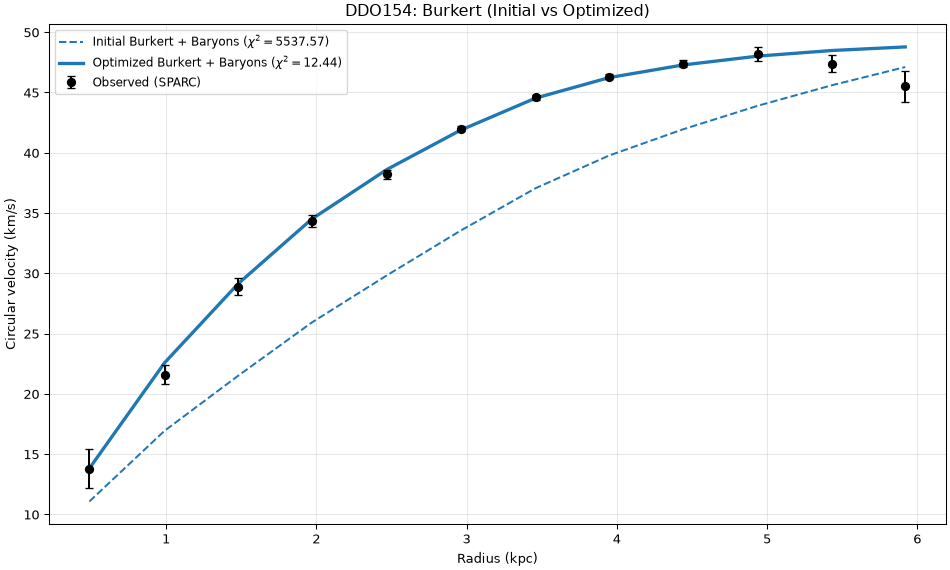

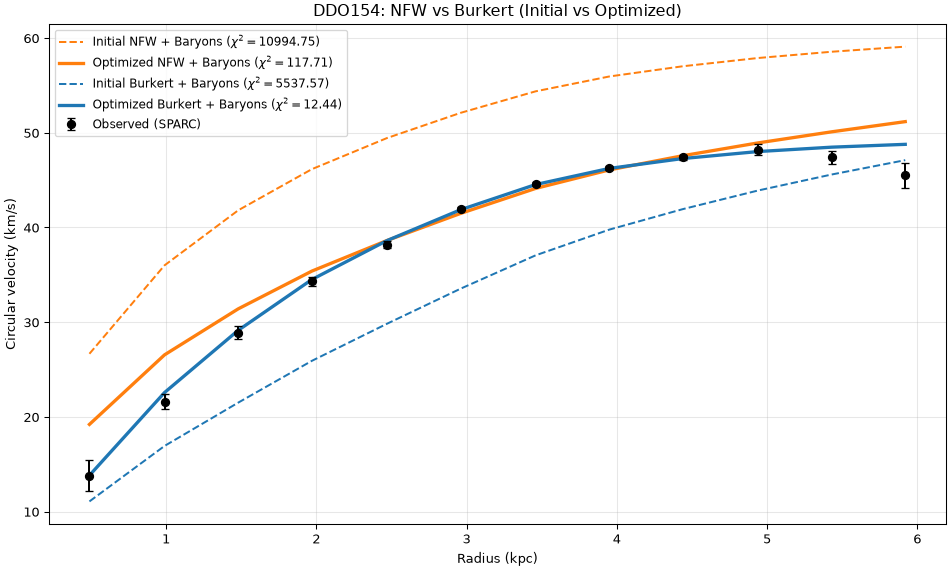

In [4]:
# Centered initialization (the unperturbed mass and concentration).
initial_params = guesses[4]
for result in fits:
    if result.summary["status"] != "success":
        print(result.summary)
        continue
    fig, ax = plot_initial_optimized_comparison([result], config, initial_params)
    fig.savefig(FIGURE_DIR / f"{GALAXY}_{result.summary['model']}_initial_vs_optimized.png", dpi=200)
    plt.show()
    plt.close(fig)

# Legacy combined comparison: two initial and two optimized total curves.
if any(result.summary["status"] == "success" for result in fits):
    fig, ax = plot_initial_optimized_comparison(fits, config, initial_params)
    fig.savefig(FIGURE_DIR / f"{GALAXY}_comparison.png", dpi=200)
    plt.show()
    plt.close(fig)


## Component and residual diagnostics
Additional decomposition plots retain the initial/optimized total curves and their raw chi-squared values.

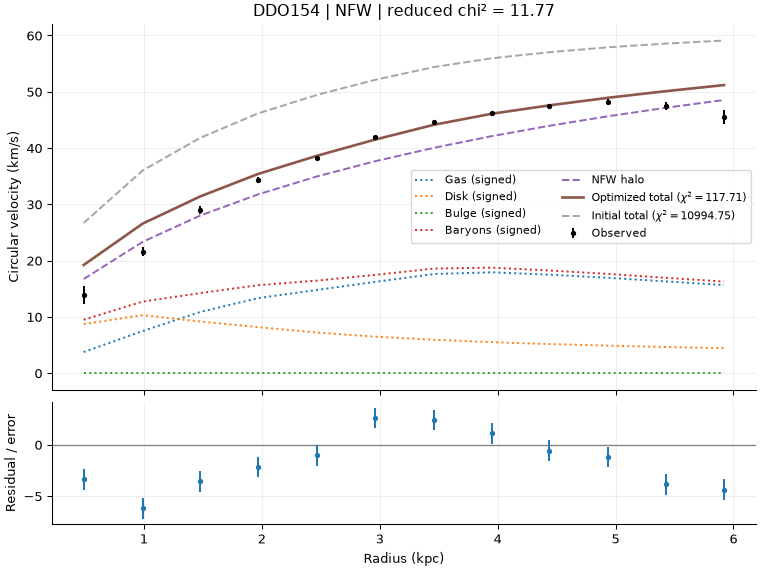

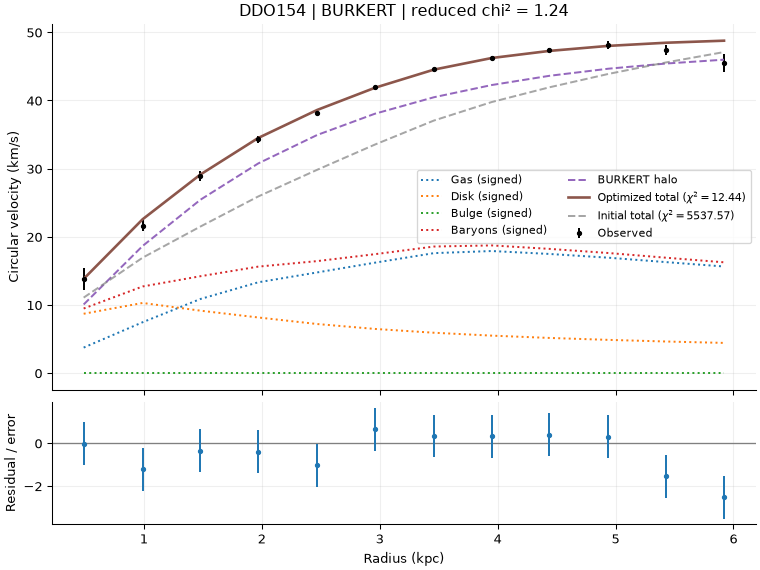

In [5]:
for result in fits:
    if result.summary["status"] != "success":
        continue
    fig, axes = plot_halo_fit(galaxy, result, config, initial_params=initial_params)
    fig.savefig(FIGURE_DIR / f"{GALAXY}_{result.summary['model']}_components.png", dpi=200)
    plt.show()
    plt.close(fig)
